In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv('data/ticket.csv')

In [2]:
print("Missing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values:
Document       0
Topic_group    0
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Document     47837 non-null  str  
 1   Topic_group  47837 non-null  str  
dtypes: str(2)
memory usage: 14.5 MB

Number of duplicate rows: 0


In [4]:
print("Dataset shape:", df.shape)
print("Dataset columns:", df.columns)
print("dataset info:", df.info())
print("head of the dataset:", df.head())
print("columns to list:", df.columns.tolist())

Dataset shape: (47837, 2)
Dataset columns: Index(['Document', 'Topic_group'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Document     47837 non-null  str  
 1   Topic_group  47837 non-null  str  
dtypes: str(2)
memory usage: 14.5 MB
dataset info: None
head of the dataset:                                             Document    Topic_group
0  connection with icon icon dear please setup ic...       Hardware
1  work experience user work experience user hi w...         Access
2  requesting for meeting requesting meeting hi p...       Hardware
3  reset passwords for external accounts re expir...         Access
4  mail verification warning hi has got attached ...  Miscellaneous
columns to list: ['Document', 'Topic_group']


In [5]:
# Count tickets in each category
print("Number of unique categories:", df["Topic_group"].nunique())

print("\nCategory distribution:")
print(df["Topic_group"].value_counts())

print("\nCategory percentages:")
print(
    (df["Topic_group"].value_counts(normalize=True) * 100)
    .round(2)
)

Number of unique categories: 8

Category distribution:
Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64

Category percentages:
Topic_group
Hardware                 28.47
HR Support               22.82
Access                   14.89
Miscellaneous            14.76
Storage                   5.81
Purchase                  5.15
Internal Project          4.43
Administrative rights     3.68
Name: proportion, dtype: float64


In [6]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate documents:",
    df["Document"].duplicated().sum()
)

print("\nSample documents:")
for i, row in df.head(10).iterrows():
    print(f"\nCategory: {row['Topic_group']}")
    print(f"Document: {row['Document'][:200]}")

Duplicate rows: 0
Duplicate documents: 0

Sample documents:

Category: Hardware
Document: connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead

Category: Access
Document: work experience user work experience user hi work experience student coming next his name much appreciate him duration thank

Category: Hardware
Document: requesting for meeting requesting meeting hi please help follow equipments cable pc cord plug

Category: Access
Document: reset passwords for external accounts re expire days hi ask help update passwords colleagues thank pm expire days importance high hi received about expiration please kindly help prolongation best rega

Category: Miscellaneous
Document: mail verification warning hi has got attached please addresses best regards monitoring analyst verification warning

Category: Miscellaneous
Document: mail please dear looks blacklisted receiving mails anymore sample attached thanks kind regards senior engi

In [7]:
print("Empty documents:", (df["Document"].str.strip() == "").sum())

print("\nText length statistics:")
print(df["Document"].str.len().describe())

print("\nMissing values:")
print(df.isnull().sum())

Empty documents: 0

Text length statistics:
count    47837.000000
mean       291.881263
std        388.171200
min          7.000000
25%        110.000000
50%        175.000000
75%        304.000000
max       7015.000000
Name: Document, dtype: float64

Missing values:
Document       0
Topic_group    0
dtype: int64


Number of categories: 8

Tickets per category:
Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64

Percentage per category:
Topic_group
Hardware                 28.47
HR Support               22.82
Access                   14.89
Miscellaneous            14.76
Storage                   5.81
Purchase                  5.15
Internal Project          4.43
Administrative rights     3.68
Name: proportion, dtype: float64


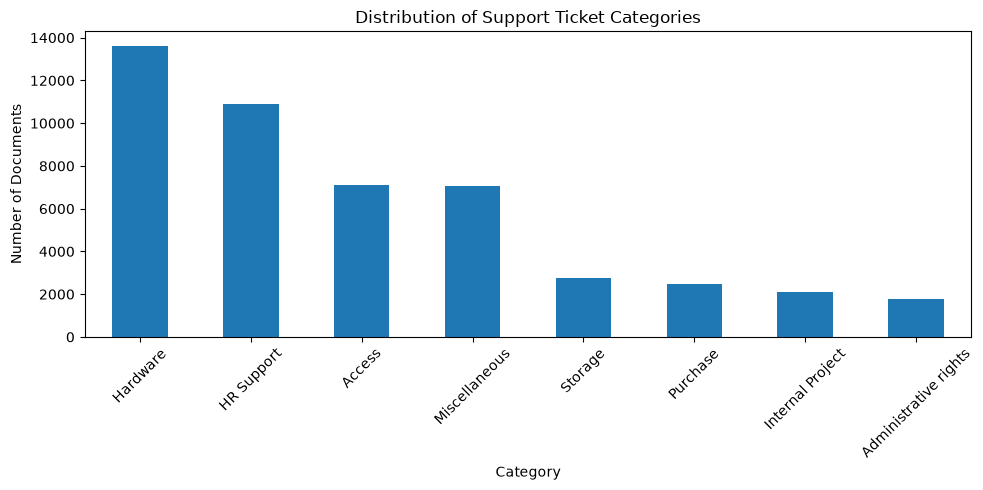

In [8]:
import matplotlib.pyplot as plt

category_counts = df["Topic_group"].value_counts()

print("Number of categories:", df["Topic_group"].nunique())
print("\nTickets per category:")
print(category_counts)

print("\nPercentage per category:")
print((df["Topic_group"].value_counts(normalize=True) * 100).round(2))

category_counts.plot(kind="bar", figsize=(10, 5))
plt.title("Distribution of Support Ticket Categories")
plt.xlabel("Category")
plt.ylabel("Number of Documents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate documents:", df["Document"].duplicated().sum())

print("\nExamples of duplicate documents:")
duplicates = df[df["Document"].duplicated(keep=False)]

display(duplicates.sort_values("Document").head(10))

Duplicate rows: 0
Duplicate documents: 0

Examples of duplicate documents:


,Document,Topic_group


In [10]:
label_counts = df.groupby("Document")["Topic_group"].nunique()

conflicting_documents = label_counts[label_counts > 1]

print(
    "Unique documents assigned to multiple categories:",
    len(conflicting_documents)
)

Unique documents assigned to multiple categories: 0


In [11]:
# Category distribution
print("Number of categories:", df["Topic_group"].nunique())
print("\nCategory counts:")
print(df["Topic_group"].value_counts())

print("\nCategory percentages:")
print(
    (df["Topic_group"].value_counts(normalize=True) * 100).round(2)
)

# Duplicate checks
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate documents:", df["Document"].duplicated().sum())

# Display category examples
print("\nSample document from each category:")
for category in df["Topic_group"].unique():
    sample = df.loc[df["Topic_group"] == category, "Document"].iloc[0]
    print(f"\n{category}: {sample[:200]}")

Number of categories: 8

Category counts:
Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64

Category percentages:
Topic_group
Hardware                 28.47
HR Support               22.82
Access                   14.89
Miscellaneous            14.76
Storage                   5.81
Purchase                  5.15
Internal Project          4.43
Administrative rights     3.68
Name: proportion, dtype: float64

Duplicate rows: 0
Duplicate documents: 0

Sample document from each category:

Hardware: connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead

Access: work experience user work experience user hi work experience student coming next his name much appreciate him duration thank

Miscellaneous: mail

In [12]:
from sklearn.model_selection import train_test_split

X = df["Document"].astype(str)
y = df["Topic_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training documents:", len(X_train))
print("Testing documents:", len(X_test))

print("\nTraining category distribution:")
print(y_train.value_counts())

Training documents: 38269
Testing documents: 9568

Training category distribution:
Topic_group
Hardware                 10893
HR Support                8732
Access                    5700
Miscellaneous             5648
Storage                   2222
Purchase                  1971
Internal Project          1695
Administrative rights     1408
Name: count, dtype: int64


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=50000,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)

Training feature matrix: (38269, 50000)
Testing feature matrix: (9568, 50000)


In [14]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


Accuracy: 0.8545

Classification Report:
                       precision    recall  f1-score   support

               Access       0.90      0.89      0.89      1425
Administrative rights       0.71      0.84      0.77       352
           HR Support       0.89      0.84      0.87      2183
             Hardware       0.86      0.81      0.83      2724
     Internal Project       0.80      0.93      0.86       424
        Miscellaneous       0.79      0.87      0.83      1412
             Purchase       0.93      0.90      0.92       493
              Storage       0.86      0.92      0.89       555

             accuracy                           0.85      9568
            macro avg       0.84      0.87      0.86      9568
         weighted avg       0.86      0.85      0.85      9568



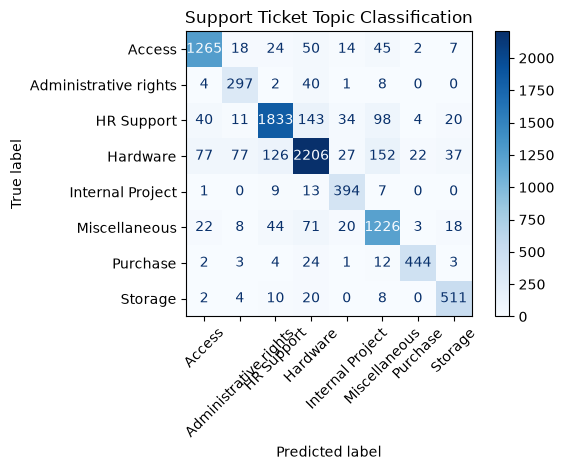

In [15]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_tfidf)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Support Ticket Topic Classification")
plt.tight_layout()
plt.show()

In [16]:
def predict_ticket(document):
    document_tfidf = tfidf.transform([document])
    prediction = model.predict(document_tfidf)[0]
    probabilities = model.predict_proba(document_tfidf)[0]

    confidence = probabilities.max() * 100

    print("Ticket:", document)
    print("Predicted category:", prediction)
    print(f"Model confidence: {confidence:.2f}%")

predict_ticket(
    "I cannot log in to my account because my password is not working"
)

predict_ticket(
    "My computer is not detecting the external hard drive"
)

predict_ticket(
    "I need permission to access a restricted company folder"
)

Ticket: I cannot log in to my account because my password is not working
Predicted category: Access
Model confidence: 99.45%
Ticket: My computer is not detecting the external hard drive
Predicted category: Hardware
Model confidence: 45.94%
Ticket: I need permission to access a restricted company folder
Predicted category: Storage
Model confidence: 97.18%


In [17]:
def predict_ticket(document):
    text_features = tfidf.transform([document])
    probabilities = model.predict_proba(text_features)[0]

    results = sorted(
        zip(model.classes_, probabilities),
        key=lambda item: item[1],
        reverse=True
    )[:3]

    print(f"\nTicket: {document}")
    print("Top predictions:")

    for category, probability in results:
        print(f"{category}: {probability:.2%}")


predict_ticket(
    "I cannot log in to my account because my password is not working"
)

predict_ticket(
    "My computer is not detecting the external hard drive"
)

predict_ticket(
    "I need permission to access a restricted company folder"
)


Ticket: I cannot log in to my account because my password is not working
Top predictions:
Access: 99.45%
Hardware: 0.19%
Administrative rights: 0.18%

Ticket: My computer is not detecting the external hard drive
Top predictions:
Hardware: 45.94%
Storage: 17.96%
Administrative rights: 11.49%

Ticket: I need permission to access a restricted company folder
Top predictions:
Storage: 97.18%
HR Support: 0.99%
Hardware: 0.76%


In [18]:

def prioritize_ticket(document):
    text = document.lower()

    critical_keywords = [
        "security breach",
        "data breach",
        "ransomware",
        "system-wide outage",
        "production outage",
        "all users are unable to access"
    ]

    high_keywords = [
        "completely blocked",
        "cannot work",
        "business operations stopped",
        "urgent deadline",
        "multiple users affected",
        "account compromised"
    ]

    low_keywords = [
        "general question",
        "feature suggestion",
        "how do i",
        "information about"
    ]

    if any(keyword in text for keyword in critical_keywords):
        return "Critical", "Immediate human review required"

    if any(keyword in text for keyword in high_keywords):
        return "High", "Prompt review recommended"

    if any(keyword in text for keyword in low_keywords):
        return "Low", "Routine handling"

    return "Medium", "Review and adjust based on impact"
    

examples = [
    "A security breach has exposed customer data",
    "All users are unable to access the production system",
    "I cannot work because my account is completely blocked",
    "How do I change my account settings?"
]

for ticket in examples:
    priority, note = prioritize_ticket(ticket)
    print(f"\nTicket: {ticket}")
    print(f"Suggested priority: {priority}")
    print(f"Action: {note}")



Ticket: A security breach has exposed customer data
Suggested priority: Critical
Action: Immediate human review required

Ticket: All users are unable to access the production system
Suggested priority: Critical
Action: Immediate human review required

Ticket: I cannot work because my account is completely blocked
Suggested priority: High
Action: Prompt review recommended

Ticket: How do I change my account settings?
Suggested priority: Low
Action: Routine handling
